# Movie Recommendation System — Phase 2

### Improving Collaborative Filtering with SVD++

**ALX ExploreAI Academy — Kaggle Project**

**Author:** Fabode Ahmed Oladele

---


## Table of Contents

1. **Project Overview**
2. **Phase 1 Benchmark**
3. **Data Loading & Validation Setup**
4. **Phase 2 — SVD++ Development**
   * 4.1 Why SVD++
   * 4.2 Data Preparation
   * 4.3 Initial SVD++
   * 4.4 Latent Factor Tuning
   * 4.5 Epoch Tuning
   * 4.6 Regularization Consideration
5. **Validation Performance & Model Comparison**
6. **Ensemble Improvement**
   * 6.1 User + Movie Bias
   * 6.2 Ensemble Weight Tuning
   * 6.3 Best Ensemble
7. **Final Model & Kaggle Submission**
   * 7.1 Final SVD++ Training
   * 7.2 Final User + Movie Bias
   * 7.3 Test Predictions
   * 7.4 Submission Validation
   * 7.5 Save the Final Submission
8. **Final Results & Conclusion**
9. **Reproducibility & Future Improvements**


## 1. Project Overview

This notebook presents **Phase 2** of the Movie Recommendation System project.
### Objective

The goal of this project is to build a collaborative filtering system that predicts ratings for **unseen user–movie pairs** and minimizes prediction error measured by **RMSE**.

### Phase 2 Approach

Phase 2 extends the Phase 1 work through the following steps:

1. Establish the Phase 1 models as a performance benchmark.
2. Introduce **SVD++** to incorporate implicit user–movie interaction information.
3. Tune the number of latent factors and training epochs.
4. Compare SVD++ with the existing User + Movie Bias model.
5. Combine the two models through an ensemble.
6. Train the selected final configuration on the complete training dataset.
7. Generate and validate the final Kaggle submission.

### Evaluation Metric

Model performance is evaluated using **Root Mean Squared Error (RMSE)**.

> **Lower RMSE indicates better predictive performance.**

The same validation framework is used throughout the experiments to make the model comparisons consistent.


## 2. Phase 1 Benchmark

Before developing the Phase 2 models, the best-performing results from Phase 1 are established as the baseline for comparison.

Phase 1 evaluated several collaborative filtering approaches using the same **RMSE** metric. These results provide a reference point for determining whether the Phase 2 improvements lead to better predictive performance.

Because RMSE is an error metric, **lower values indicate better performance**.


In [4]:
import pandas as pd

phase1_results = pd.DataFrame({
    "Model": [
        "Global Mean Baseline",
        "User + Movie Bias",
        "Tuned User + Movie Bias",
        "Initial SVD",
        "Tuned SVD",
        "Weighted Bias + SVD Ensemble"
    ],
    "Key Parameters": [
        "Overall mean rating",
        "User reg=10, Movie reg=20",
        "User reg=10, Movie reg=20",
        "50 factors, 20 epochs, random_state=42",
        "20 factors, 20 epochs, reg=0.05",
        "75% Bias + 25% SVD"
    ],
    "Validation RMSE": [
        1.060875,
        0.880608,
        0.880417,
        0.906448,
        0.898068,
        0.877906
    ]
})

phase1_results

,Model,Key Parameters,Validation RMSE
0,Global Mean Baseline,Overall mean rating,1.060875
1,User + Movie Bias,"User reg=10, Movie reg=20",0.880608
2,Tuned User + Movie Bias,"User reg=10, Movie reg=20",0.880417
3,Initial SVD,"50 factors, 20 epochs, random_state=42",0.906448
4,Tuned SVD,"20 factors, 20 epochs, reg=0.05",0.898068
5,Weighted Bias + SVD Ensemble,75% Bias + 25% SVD,0.877906


### Phase 1 Benchmark Results

The Phase 1 experiments established the following validation results:

| Model                   | Validation RMSE |
| ----------------------- | --------------: |
| Global Mean Baseline    |        1.060875 |
| User + Movie Bias       |        0.880608 |
| Tuned User + Movie Bias |    **0.880417** |
| Initial SVD             |        0.906448 |
| Tuned SVD               |        0.898068 |

The **Tuned User + Movie Bias** model achieved the lowest RMSE among the Phase 1 individual models, with a validation RMSE of **0.880417**.

This result provides the main benchmark for evaluating the Phase 2 improvements.


## 3. Data Loading & Validation Setup

The MovieLens dataset is prepared for Phase 2 modelling using the same validation approach established for the earlier experiments.

The training data contains historical user–movie ratings, while the test data contains user–movie pairs for which ratings must be predicted.

### 3.1 Load the Datasets

The training and test datasets are loaded using pandas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [17]:
# Load training and test data

train_path = "train.csv"
test_path = "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (10000038, 4)
Test shape: (5000019, 2)


The datasets contain:

* **10,000,038** user–movie ratings in the training set.
* **5,000,019** user–movie pairs in the test set.

The scale of the dataset makes computational efficiency an important consideration when developing and tuning the recommendation models.


### 3.2 Dataset Inspection

Before modelling, the structure and quality of the datasets are examined to confirm that the required variables are available and that the data is suitable for modelling.


In [6]:
# Inspect the first few rows

print("Training data:")
display(train_df.head())

print("\nTest data:")
display(test_df.head())

Training data:


,userId,movieId,rating,timestamp
0,5163,57669,4.0,1518349992
1,106343,5,4.5,1206238739
2,146790,5459,5.0,1076215539
3,106362,32296,2.0,1423042565
4,9041,366,3.0,833375837



Test data:


,userId,movieId
0,1,2011
1,1,4144
2,1,5767
3,1,6711
4,1,7318


### Dataset Structure

The training data contains:

- userId
- movieId
- rating
- timestamp

The test data contains:

- userId
- movieId

This is expected because the test set contains the ratings that the model needs to predict.


### 3.3 Data Types and Missing Values

The data types and missing values are examined to ensure that the variables required for modelling are available and correctly formatted.

Special attention is given to:

* `userId`
* `movieId`
* `rating`

Missing values could affect model training and prediction quality, so this check is performed before further analysis.


In [5]:
# Check data types and missing values

print("Training information:")
train_df.info()

print("\nMissing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in test data:")
print(test_df.isnull().sum())

Training information:
<class 'pandas.DataFrame'>
RangeIndex: 10000038 entries, 0 to 10000037
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 305.2 MB

Missing values in training data:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in test data:
userId     0
movieId    0
dtype: int64


### Interpretation

The inspection shows that the datasets contain no missing values in the variables required for modelling.

The rating variable is stored as a numeric data type, while user and movie identifiers are represented as integers.

Therefore, the dataset is suitable for collaborative filtering without additional cleaning.


### 3.4 Rating Distribution

The distribution of ratings is examined to understand the scale and central tendency of the data.

This provides useful information about typical user behaviour and establishes the rating range used throughout the recommendation models.


In [6]:
# Basic statistics for the training ratings

print("Rating statistics:")
print(train_df["rating"].describe())

Rating statistics:
count    1.000004e+07
mean     3.533395e+00
std      1.061124e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64


### Rating Summary

The ratings range from **0.5 to 5.0**, with an average rating of approximately **3.53**.

The median rating is **3.5**, indicating that users generally provide moderate to positive ratings.

These statistics are important because they define the valid prediction range for the recommendation models.


### 3.5 Dataset Scale

The number of unique users and movies provides an indication of the size and complexity of the recommendation problem.


In [7]:
# Number of unique users and movies

n_users = train_df["userId"].nunique()
n_movies = train_df["movieId"].nunique()

print(f"Unique users: {n_users:,}")
print(f"Unique movies: {n_movies:,}")

Unique users: 162,541
Unique movies: 48,213


### Dataset Scale Summary

The dataset contains:

* **162,541 users**
* **48,213 movies**

This large number of users and items creates a sparse user–movie interaction matrix, making collaborative filtering methods such as SVD and SVD++ appropriate modelling approaches.


### 3.6 Train–Validation Split

The training data is divided into training and validation sets.

The validation set is used to evaluate model performance on unseen ratings while preserving a large portion of the data for training.

An 80/20 split is used to maintain consistency with the Phase 1 experiments.


In [19]:
# Create training and validation sets

train_data, validation_data = train_test_split(
    train_df,
    test_size = 0.2,
    random_state = 42
)

print("Training set shape:", train_data.shape)
print("validation set shape:",  validation_data.shape)

Training set shape: (8000030, 4)
validation set shape: (2000008, 4)


### Interpretation

The data split produced:

* Approximately **8 million ratings** for model training.
* Approximately **2 million ratings** for validation.

This validation framework is used consistently throughout the Phase 2 experiments, ensuring that all models are evaluated under the same conditions.


## 4. Phase 2 — SVD++ Development

### 4.1 Why SVD++?

Phase 1 showed that both bias-based models and latent-factor models can capture useful patterns in user–movie ratings.

Phase 2 introduces **SVD++**, an extension of SVD designed to incorporate not only explicit ratings but also information from a user's historical interactions with movies.

This provides an opportunity to capture additional user preferences that may not be fully represented by standard SVD.

The objective is to determine whether SVD++ can improve validation performance over the Phase 1 benchmark.


### 4.2 SVD++ Data Preparation

The same training and validation split established in Section 3 is used for the SVD++ experiments.

The data is converted into the format required by the **Surprise** recommendation framework, using `userId`, `movieId`, and `rating`.

Keeping the same validation data ensures that the SVD++ results can be compared fairly with the Phase 1 models.


In [10]:
# Select the columns required by Surprise

svdpp_train_df = train_data[["userId", "movieId", "rating"]].copy()

svdpp_validation_df = validation_data[["userId", "movieId", "rating"]].copy()

print("SVD++ training data shape:", svdpp_train_df.shape)
print("SVD++ validation data shape:", svdpp_validation_df.shape)

SVD++ training data shape: (8000030, 3)
SVD++ validation data shape: (2000008, 3)


### Interpretation — SVD++ data preparation

The training and validation datasets were successfully converted to the three columns required by SVD++: `userId`, `movieId`, and `rating`.

- **8,000,030 ratings** are available for training.
- **2,000,008 ratings** are reserved for validation.
The timestamp was correctly excluded because SVD++ does not use it in this experiment.


In [11]:
from surprise import SVDpp, Dataset, Reader
# Define the rating scale

reader = Reader(rating_scale=(0.5, 5.0))

# Convert the training data into a Surprise dataset

svdpp_data = Dataset.load_from_df(
    svdpp_train_df[["userId", "movieId", "rating"]],
    reader
)

# Build the full training set required by SVD++

svdpp_trainset = svdpp_data.build_full_trainset()

print("Number of users:", svdpp_trainset.n_users)
print("Number of items:", svdpp_trainset.n_items)
print("Number of ratings:", svdpp_trainset.n_ratings)

Number of users: 162538
Number of items: 45438
Number of ratings: 8000030


### 4.3 Initial SVD++ Experiment

An initial SVD++ model is trained to establish a starting point for Phase 2.

The experiment uses:

* **Latent factors:** 20
* **Training epochs:** 3
* **Random state:** 42

This configuration provides a computationally manageable starting point before investigating the effect of the main SVD++ hyperparameters.


In [12]:
import time
# Initialize the SVD++ model

print("Initialize the SVD++ model...")
svdpp_model_20_3 = SVDpp(
    n_factors=20,
    n_epochs=3,
    random_state=42
)
# Start timer
start_time = time.time()

# Train the model
print("Training SVD++...")
svdpp_model_20_3.fit(svdpp_trainset)

# Stop timer
end_time = time.time()

# Calculate training time
training_time = end_time - start_time

print("SVD++ training completed.")
print(f"Training time: {training_time / 60:.2f} minutes")

Initialize the SVD++ model...
Training SVD++...
SVD++ training completed.
Training time: 16.26 minutes


### Initial SVD++ Result

The initial SVD++ experiment provides a baseline for the Phase 2 tuning process.

Rather than assuming that a more complex model will automatically perform better, the subsequent experiments evaluate different configurations using the same validation RMSE metric.

The main parameters investigated are **the number of latent factors** and **the number of training epochs**.


In [13]:
# Generate SVD++ predictions on the validation set

svdpp_predictions_20_3 = [
    svdpp_model_20_3.predict(user_id, movie_id, rating).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]

# Calculate RMSE

svdpp_rmse_20_3 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        svdpp_predictions_20_3
    )
)

print(f"SVD++ Validation RMSE for 20 factors, 3 training epochs : {svdpp_rmse_20_3:.6f}")

SVD++ Validation RMSE for 20 factors, 3 training epochs : 0.865322


### 4.4 Latent Factor Tuning

The number of latent factors controls the number of hidden dimensions used to represent users and movies.

A larger number of factors can represent more complex user–movie relationships, but it also increases computational cost. Therefore, several configurations are tested while keeping the number of training epochs fixed at **3**.

The following factor values were evaluated:

**10, 20, 30, 40, and 80**

Each configuration is evaluated using the same validation set and **RMSE** metric.


In [12]:
import time
# Initialize the SVD++ model

print("Initialize the SVD++ model...")
svdpp_model_10_3 = SVDpp(
    n_factors=10,
    n_epochs=3,
    random_state=42
)
# Start timer
start_time = time.time()

# Train the model
print("Training SVD++...")
svdpp_model_10_3.fit(svdpp_trainset)

# Stop timer
end_time = time.time()

# Calculate training time
training_time = end_time - start_time

print("SVD++ training completed.")
print(f"Training time: {training_time / 60:.2f} minutes")

Initialize the SVD++ model...
Training SVD++...
SVD++ training completed.
Training time: 11.42 minutes


In [13]:
# Generate SVD++ predictions on the validation set

svdpp_predictions_10_3 = [
    svdpp_model_10_3.predict(user_id, movie_id, rating).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]

# Calculate RMSE

svdpp_rmse_10_3 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        svdpp_predictions_10_3
    )
)

print(f"SVD++ Validation RMSE for 10 factors, 3 training epochs : {svdpp_rmse_10_3:.6f}")

SVD++ Validation RMSE for 10 factors, 3 training epochs : 0.866470


In [14]:
import time
# Initialize the SVD++ model

print("Initialize the SVD++ model...")
svdpp_model_30_3 = SVDpp(
    n_factors=30,
    n_epochs=3,
    random_state=42
)
# Start timer
start_time = time.time()

# Train the model
print("Training SVD++...")
svdpp_model_30_3.fit(svdpp_trainset)

# Stop timer
end_time = time.time()

# Calculate training time
training_time = end_time - start_time

print("SVD++ training completed.")
print(f"Training time: {training_time / 60:.2f} minutes")

Initialize the SVD++ model...
Training SVD++...
SVD++ training completed.
Training time: 20.19 minutes


In [15]:
# Generate SVD++ predictions on the validation set

svdpp_predictions_30_3 = [
    svdpp_model_30_3.predict(user_id, movie_id, rating).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]

# Calculate RMSE

svdpp_rmse_30_3 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        svdpp_predictions_30_3
    )
)

print(f"SVD++ Validation RMSE for 30 factors, 3 training epochs : {svdpp_rmse_30_3:.6f}")

SVD++ Validation RMSE for 30 factors, 3 training epochs : 0.864369


In [13]:
import time
# Initialize the SVD++ model

print("Initialize the SVD++ model...")
svdpp_model_40_3 = SVDpp(
    n_factors=40,
    n_epochs=3,
    random_state=42
)
# Start timer
start_time = time.time()

# Train the model
print("Training SVD++...")
svdpp_model_40_3.fit(svdpp_trainset)

# Stop timer
end_time = time.time()

# Calculate training time
training_time = end_time - start_time

print("SVD++ training completed.")
print(f"Training time: {training_time / 60:.2f} minutes")

Initialize the SVD++ model...
Training SVD++...
SVD++ training completed.
Training time: 26.46 minutes


In [15]:
# Generate SVD++ predictions on the validation set

svdpp_predictions_40_3 = [
    svdpp_model_40_3.predict(user_id, movie_id, rating).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]

# Calculate RMSE

svdpp_rmse_40_3 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        svdpp_predictions_40_3
    )
)

print(f"SVD++ Validation RMSE for 40 factors, 3 training epochs : {svdpp_rmse_40_3:.6f}")

SVD++ Validation RMSE for 40 factors, 3 training epochs : 0.863821


In [12]:
import time
# Initialize the SVD++ model

print("Initialize the SVD++ model...")
svdpp_model_80_3 = SVDpp(
    n_factors=80,
    n_epochs=3,
    random_state=42
)
# Start timer
start_time = time.time()

# Train the model
print("Training SVD++...")
svdpp_model_80_3.fit(svdpp_trainset)

# Stop timer
end_time = time.time()

# Calculate training time
training_time = end_time - start_time

print("SVD++ training completed.")
print(f"Training time: {training_time / 60:.2f} minutes")

Initialize the SVD++ model...
Training SVD++...
SVD++ training completed.
Training time: 43.67 minutes


In [13]:
# Generate SVD++ predictions on the validation set

svdpp_predictions_80_3 = [
    svdpp_model_80_3.predict(user_id, movie_id, rating).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]

# Calculate RMSE

svdpp_rmse_80_3 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        svdpp_predictions_80_3
    )
)

print(f"SVD++ Validation RMSE for 80 factors, 3 training epochs : {svdpp_rmse_80_3:.6f}")

SVD++ Validation RMSE for 80 factors, 3 training epochs : 0.863750


### Latent Factor Tuning Results

The experiments show that increasing the number of latent factors generally improved SVD++ performance, although the improvement became very small at higher factor values.

| Latent Factors | Validation RMSE |
| -------------: | --------------: |
|             10 |        0.866470 |
|             20 |        0.865322 |
|             30 |        0.864369 |
|         **40** |    **0.863821** |
|             80 |        0.863750 |

The **40-factor configuration** was selected as the practical choice for further experimentation.

Although 80 factors produced a slightly lower RMSE, the improvement was negligible compared with the additional computational cost.

This demonstrates the importance of considering both predictive performance and computational efficiency when tuning a model on a large dataset.


In [12]:
factor_results = pd.DataFrame({
    "n_factors": [10, 20, 30, 40, 80],
    "n_epochs": [3, 3, 3, 3, 3],
    "RMSE": [0.866470, 0.865322, 0.864369, 0.863821, 0.863750]
})

factor_results.sort_values("RMSE")

,n_factors,n_epochs,RMSE
4,80,3,0.863750
3,40,3,0.863821
2,30,3,0.864369
1,20,3,0.865322
0,10,3,0.866470


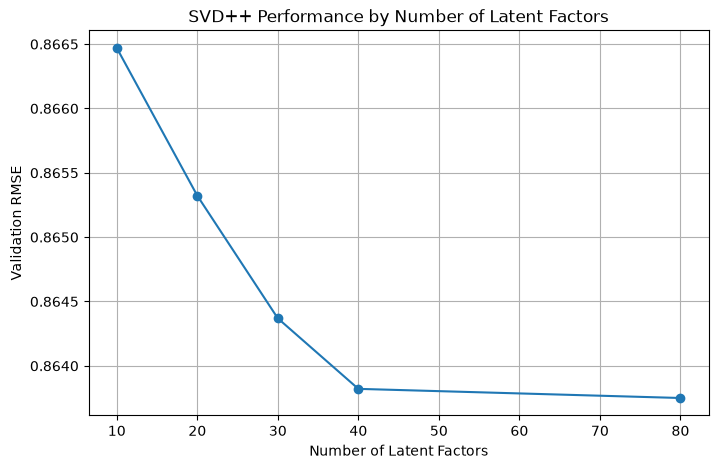

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    factor_results["n_factors"],
    factor_results["RMSE"],
    marker="o"
)

plt.xlabel("Number of Latent Factors")
plt.ylabel("Validation RMSE")
plt.title("SVD++ Performance by Number of Latent Factors")
plt.grid(True)

# Save the visualization
plt.savefig("svdpp_factor_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

### 4.5 Training Epoch Tuning

After selecting **40 latent factors**, the number of training epochs is investigated.

The number of epochs determines how many passes the algorithm makes while learning the model parameters. Increasing the number of epochs can improve learning, but excessive training may provide little additional benefit while increasing computational cost.

The following configurations were evaluated:

**2, 3, 5, and 8 epochs**

The number of latent factors is kept fixed at **40** so that the effect of training duration can be evaluated independently.


In [14]:
svdpp_40_2 = SVDpp(
    n_factors=40,
    n_epochs=2,
    random_state=42
)

svdpp_40_2.fit(svdpp_trainset)

predictions_40_2 = [
    svdpp_40_2.predict(user_id, movie_id).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]

rmse_40_2 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        predictions_40_2
    )
)

print(f"SVD++ Validation RMSE for 40 factors, 2 training epochs : {rmse_40_2:.6f}")

SVD++ Validation RMSE for 40 factors, 2 training epochs : 0.873918


In [14]:
print("Initializing SVD++...")
svdpp_40_5 = SVDpp(
    n_factors=40,
    n_epochs=5,
    random_state=42
)

print("Training SVD++...")
svdpp_40_5.fit(svdpp_trainset)
print("Training SVD++ Completed...")

print("SVD++ Validation started...")
predictions_40_5 = [
    svdpp_40_5.predict(user_id, movie_id).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]
print("SVD++ Validation Complteted...")

print("Calculating RMSE...")
rmse_40_5 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        predictions_40_5
    )
)

print(f"SVD++ Validation RMSE for 40 factors, 5 training epochs : {rmse_40_5:.6f}")
print("Completed")

Initializing SVD++...
Training SVD++...
Training SVD++ Completed...
SVD++ Validation started...
SVD++ Validation Complteted...
Calculating RMSE...
SVD++ Validation RMSE for 40 factors, 5 training epochs : 0.852306
Completed


In [12]:
print("Initializing SVD++...")
svdpp_40_8 = SVDpp(
    n_factors=40,
    n_epochs=8,
    random_state=42
)

print("Training SVD++...")
svdpp_40_8.fit(svdpp_trainset)
print("Training SVD++ Completed...")

print("SVD++ Validation started...")
predictions_40_8 = [
    svdpp_40_8.predict(user_id, movie_id).est
    for user_id, movie_id, rating in validation_data[
        ["userId", "movieId", "rating"]
    ].itertuples(index=False, name=None)
]
print("SVD++ Validation Complteted...")

print("Calculating RMSE...")
rmse_40_8 = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        predictions_40_8
    )
)

print(f"SVD++ Validation RMSE for 40 factors, 8 training epochs : {rmse_40_8:.6f}")
print("Completed")

Initializing SVD++...
Training SVD++...
Training SVD++ Completed...
SVD++ Validation started...
SVD++ Validation Complteted...
Calculating RMSE...
SVD++ Validation RMSE for 40 factors, 5 training epochs : 0.842391
Completed


### Training Epoch Tuning Results

The epoch experiments produced the following validation RMSE values:

| Training Epochs | Validation RMSE |
| --------------: | --------------: |
|               2 |        0.873918 |
|               3 |        0.863821 |
|               5 |        0.852306 |
|           **8** |    **0.842391** |
Performance improved as the number of epochs increased from 2 to 8.

Therefore, **40 latent factors and 8 epochs** were selected as the SVD++ configuration for the next stage of the project.

The resulting validation RMSE was **0.842391**.


In [14]:
epoch_results = pd.DataFrame({
    "n_factors": [40, 40, 40, 40],
    "n_epochs": [2, 3, 5, 8],
    "RMSE": [0.873918, 0.863821, 0.852306, 0.842391]
})

epoch_results.sort_values("RMSE")


,n_factors,n_epochs,RMSE
3,40,8,0.842391
4,40,10,0.842391
2,40,5,0.852306
1,40,3,0.863821
0,40,2,0.873918


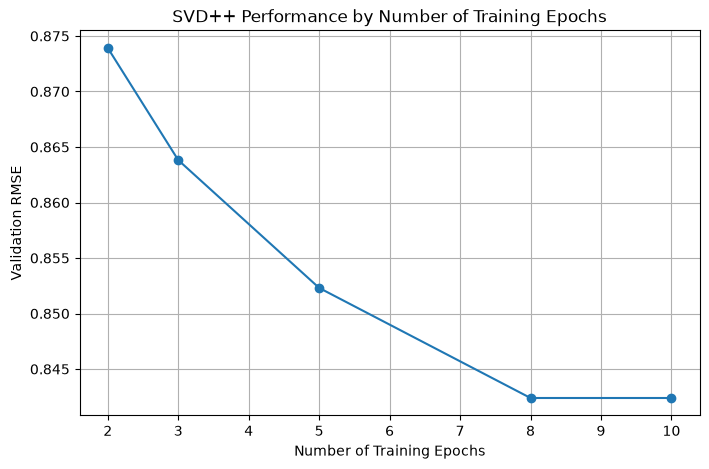

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_results["n_epochs"],
    epoch_results["RMSE"],
    marker="o"
)

plt.xlabel("Number of Training Epochs")
plt.ylabel("Validation RMSE")
plt.title("SVD++ Performance by Number of Training Epochs")
plt.grid(True)

# Save the visualization
plt.savefig("svdpp_epochs_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

### 4.6 Regularization Consideration

Regularization is an important component of matrix-factorization models because it helps control model complexity and reduce overfitting.

During the SVD++ experiments, regularization parameters were considered as a possible tuning direction. However, the installed version of the **Surprise SVD++ implementation** used in this project does not expose the additional SVD++ regularization parameters required for direct tuning through the model constructor.

Therefore, regularization tuning was **not included in the final SVD++ experiments**.

The Phase 2 model selection instead focused on the parameters that were directly available and computationally practical to evaluate: **latent factors and training epochs**.


### Best SVD++ Configuration

Based on the experiments conducted, the selected SVD++ configuration is:

* **Latent factors:** 40
* **Training epochs:** 8
* **Random state:** 42
* **Validation RMSE:** **0.842391**

This result represents a substantial improvement over the Phase 1 benchmark and provides the foundation for the ensemble experiment in the next section.


## 5. Validation Performance & Model Comparison

The tuned SVD++ model is compared with the Phase 1 models using the same validation framework and RMSE metric.

This comparison shows whether the Phase 2 approach improves predictive performance before combining SVD++ with the User + Movie Bias model.


In [16]:
phase2_results = pd.DataFrame({
    "Model": [
        "Global Mean Baseline",
        "User + Movie Bias",
        "Tuned User + Movie Bias",
        "Initial SVD",
        "Tuned SVD",
        "Weighted Bias + SVD Ensemble",
        "Tuned SVD++"
    ],
    "Key Parameters": [
        "—",
        "Original parameters",
        "User reg=10, Movie reg=20",
        "50 factors, 20 epochs, random_state=42",
        "20 factors, 20 epochs, reg=0.05",
        "75% Bias + 25% SVD",
        "40 factors, 8 epochs"
    ],
    "Validation RMSE": [
        1.060875,
        0.880608,
        0.880417,
        0.906448,
        0.898068,
        0.877906,
        0.842391
    ]
})

phase2_results.sort_values("Validation RMSE")

,Model,Key Parameters,Validation RMSE
6,Tuned SVD++,"40 factors, 8 epochs",0.842391
5,Weighted Bias + SVD Ensemble,75% Bias + 25% SVD,0.877906
2,Tuned User + Movie Bias,"User reg=10, Movie reg=20",0.880417
1,User + Movie Bias,Original parameters,0.880608
4,Tuned SVD,"20 factors, 20 epochs, reg=0.05",0.898068
3,Initial SVD,"50 factors, 20 epochs, random_state=42",0.906448
0,Global Mean Baseline,—,1.060875


### Interpretation

The tuned SVD++ model achieved a validation RMSE of **0.842391**, which is lower than the Phase 1 best result of **0.877906** from the Weighted Bias + SVD Ensemble.

This represents an improvement of approximately **0.0355 RMSE** on the validation set. The result indicates that incorporating implicit user–item interaction information through SVD++ provided additional predictive value beyond the approaches evaluated in Phase 1.

The tuned SVD++ model therefore becomes the current strongest individual model in the project and will be used as the basis for further improvement.


## 6. Ensemble Improvement

The tuned SVD++ model provides a strong Phase 2 result, but it captures user–movie relationships differently from the User + Movie Bias model.

The next experiment combines their predictions to determine whether the two models provide complementary information.

The ensemble prediction is calculated as a weighted combination of:

* **SVD++ predictions**
* **User + Movie Bias predictions**

Different SVD++ weights are tested while the remaining weight is assigned to the User + Movie Bias model.

The objective is to identify a combination that produces a lower validation RMSE than either individual model.


In [18]:
# Reuse the selected 40-factor, 8-epoch SVD++ validation predictions

svdpp_predictions = np.asarray(predictions_40_8)

print("SVD++ validation predictions ready for ensemble.")
print("Number of predictions:", len(svdpp_predictions))


Initializing final SVD++ model...
Final SVD++ model Started...
Final SVD++ model trained successfully.
Final SVD++ model prediction started...
SVD++ validation predictions generated successfully.
Number of predictions: 2000008


### 6.1 User + Movie Bias

The tuned User + Movie Bias model from Phase 1 is used as the second component of the ensemble.

The model uses:

* **User regularization:** 10
* **Movie regularization:** 20

The model is trained using the same validation framework as SVD++, ensuring that its predictions can be combined fairly with the SVD++ predictions.


### 6.1.1 Calculate Global Mean


In [20]:
# Calculate the global mean rating from the training data

global_mean_train = train_data["rating"].mean()

print(f"Training Global Mean: {global_mean_train:.6f}")

Training Global Mean: 3.533469


### 6.1.2 Calculate User and Movie Statistics


In [20]:
# Calculate user-level rating statistics

user_stats = (
    train_data.groupby("userId")["rating"]
    .agg(["sum", "count"])
)

# Calculate movie-level rating statistics

movie_stats = (
    train_data.groupby("movieId")["rating"]
    .agg(["sum", "count"])
)

print("User statistics calculated.")
print("Movie statistics calculated.")

print("Number of users:", len(user_stats))
print("Number of movies:", len(movie_stats))

User statistics calculated.
Movie statistics calculated.
Number of users: 162538
Number of movies: 45438


### 6.1.3 Generate User + Movie Bias Predictions


In [21]:
# Best User + Movie Bias configuration from Phase 1

user_reg = 10
movie_reg = 20

best_user_bias = (
    (user_stats["sum"] - user_stats["count"] * global_mean_train)
    / (user_stats["count"] + user_reg)
)

best_movie_bias = (
    (movie_stats["sum"] - movie_stats["count"] * global_mean_train)
    / (movie_stats["count"] + movie_reg)
)

bias_predictions = (
    global_mean_train
    + validation_data["userId"].map(best_user_bias).fillna(0).values
    + validation_data["movieId"].map(best_movie_bias).fillna(0).values
)

print("User + Movie Bias predictions generated successfully.")
print("Number of predictions:", len(bias_predictions))

User + Movie Bias predictions generated successfully.
Number of predictions: 2000008


### 6.1.4 Check Individual Model RMSEs


In [22]:
bias_rmse = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        bias_predictions
    )
)

svdpp_rmse = np.sqrt(
    mean_squared_error(
        validation_data["rating"],
        svdpp_predictions
    )
)

print(f"Bias Model RMSE: {bias_rmse:.6f}")
print(f"SVD++ RMSE: {svdpp_rmse:.6f}")

Bias Model RMSE: 0.880417
SVD++ RMSE: 0.842391


### 6.2 Ensemble Weight Tuning

The contribution of SVD++ to the ensemble is varied while the User + Movie Bias contribution is adjusted accordingly.

The SVD++ weights tested are:

**0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, and 0.95**

For each configuration:

$$
\text{Ensemble Prediction}
=
w(\text{SVD++}) + (1-w)(\text{Bias})
$$

The resulting predictions are evaluated using validation RMSE.


In [23]:
ensemble_results = []

weights = [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

for svdpp_weight in weights:

    bias_weight = 1 - svdpp_weight

    ensemble_predictions = (
        svdpp_weight * svdpp_predictions
        + bias_weight * bias_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation_data["rating"],
            ensemble_predictions
        )
    )

    ensemble_results.append({
        "SVD++ Weight": svdpp_weight,
        "Bias Weight": bias_weight,
        "RMSE": rmse
    })

ensemble_results_df = pd.DataFrame(ensemble_results)

ensemble_results_df.sort_values("RMSE")

,SVD++ Weight,Bias Weight,RMSE
2,0.70,0.30,0.834601
3,0.75,0.25,0.834739
4,0.80,0.20,0.835343
1,0.60,0.40,0.835725
5,0.85,0.15,0.836412
6,0.90,0.10,0.837945
0,0.50,0.50,0.838707
7,0.95,0.05,0.839939


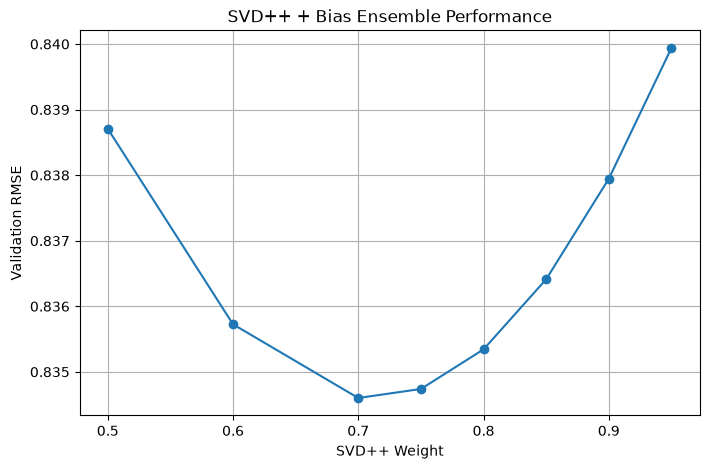

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    ensemble_results_df["SVD++ Weight"],
    ensemble_results_df["RMSE"],
    marker="o"
)

plt.xlabel("SVD++ Weight")
plt.ylabel("Validation RMSE")
plt.title("SVD++ + Bias Ensemble Performance")
plt.grid(True)

plt.savefig(
    "svdpp_bias_ensemble_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.3 Best Ensemble Result

The ensemble results show that combining SVD++ with the User + Movie Bias model improves validation performance compared with SVD++ alone.

| SVD++ Weight | Bias Weight | Validation RMSE |
| -----------: | ----------: | --------------: |
|         0.50 |        0.50 |        0.838707 |
|         0.60 |        0.40 |        0.835725 |
|     **0.70** |    **0.30** |    **0.834601** |
|         0.75 |        0.25 |        0.834739 |
|         0.80 |        0.20 |        0.835343 |
|         0.85 |        0.15 |        0.836412 |
|         0.90 |        0.10 |        0.837945 |
|         0.95 |        0.05 |        0.839939 |

The best validation result was achieved with **70% SVD++ and 30% User + Movie Bias**, producing an RMSE of **0.834601**.

This improves on the tuned SVD++ model's RMSE of **0.842391** by approximately **0.0078**.

Increasing the SVD++ contribution beyond 70% did not improve validation performance. This indicates that the User + Movie Bias model contributes complementary information to the SVD++ predictions.

Therefore, the **70% SVD++ + 30% User + Movie Bias** configuration is selected as the final Phase 2 ensemble.


## 7. Final Model & Kaggle Submission

The validation experiments identified the **70% SVD++ + 30% User + Movie Bias** ensemble as the selected Phase 2 configuration.

The final model is now trained using the complete training dataset before generating predictions for the Kaggle test set.

### 7.1 Final SVD++ Training

The selected SVD++ configuration is retrained using all available training ratings.

The final configuration is:

* **Latent factors:** 40
* **Training epochs:** 8
* **Random state:** 42

Training on the complete dataset allows the model to use all available user–movie rating information before making predictions for the unseen test pairs.


In [3]:
# Build the full training set for the final SVD++ model
from surprise import SVDpp, Dataset, Reader
# Define the rating scale

reader = Reader(rating_scale=(0.5, 5.0))

full_svdpp_data = Dataset.load_from_df(
    train_df[["userId", "movieId", "rating"]],
    reader
)

full_svdpp_trainset = full_svdpp_data.build_full_trainset()

print("Full SVD++ training set ready.")
print("Users:", full_svdpp_trainset.n_users)
print("Movies:", full_svdpp_trainset.n_items)
print("Ratings:", full_svdpp_trainset.n_ratings)

Full SVD++ training set ready.
Users: 162541
Movies: 48213
Ratings: 10000038


In [4]:
# Train the final SVD++ model

final_svdpp = SVDpp(
    n_factors=40,
    n_epochs=8,
    random_state=42
)

print("Training final SVD++ model...")

final_svdpp.fit(full_svdpp_trainset)

print("Final SVD++ training completed.")

Training final SVD++ model...
Final SVD++ training completed.


### 7.2 Final User + Movie Bias

The User + Movie Bias model is also calculated using the complete training dataset.

The selected regularization settings are:

* **User regularization:** 10
* **Movie regularization:** 20

These predictions form the second component of the final ensemble.


In [6]:
# Calculate global mean from the complete training dataset

global_mean_full = train_df["rating"].mean()

# Calculate user-level statistics
user_stats_full = (
    train_df.groupby("userId")["rating"]
    .agg(["sum", "count"])
)

# Calculate movie-level statistics
movie_stats_full = (
    train_df.groupby("movieId")["rating"]
    .agg(["sum", "count"])
)

print(f"Full Training Global Mean: {global_mean_full:.6f}")
print("Users:", len(user_stats_full))
print("Movies:", len(movie_stats_full))

Full Training Global Mean: 3.533395
Users: 162541
Movies: 48213


In [7]:
# Final User + Movie Bias configuration

user_reg = 10
movie_reg = 20

final_user_bias = (
    (user_stats_full["sum"] - user_stats_full["count"] * global_mean_full)
    / (user_stats_full["count"] + user_reg)
)

final_movie_bias = (
    (movie_stats_full["sum"] - movie_stats_full["count"] * global_mean_full)
    / (movie_stats_full["count"] + movie_reg)
)

print("Final User + Movie Bias model calculated successfully.")

Final User + Movie Bias model calculated successfully.


In [8]:
# Generate predictions from the final SVD++ model

final_svdpp_predictions = np.array([
    final_svdpp.predict(user_id, movie_id).est
    for user_id, movie_id in test_df[["userId", "movieId"]].itertuples(
        index=False,
        name=None
    )
])

print("Final SVD++ test predictions generated.")
print("Number of predictions:", len(final_svdpp_predictions))

Final SVD++ test predictions generated.
Number of predictions: 5000019


In [9]:
# Generate predictions from the final User + Movie Bias model

final_bias_predictions = (
    global_mean_full
    + test_df["userId"].map(final_user_bias).fillna(0).values
    + test_df["movieId"].map(final_movie_bias).fillna(0).values
)

print("Final User + Movie Bias test predictions generated.")
print("Number of predictions:", len(final_bias_predictions))

Final User + Movie Bias test predictions generated.
Number of predictions: 5000019


### 7.3 Test Predictions

Predictions are generated for all user–movie pairs in the Kaggle test dataset.

The final prediction is calculated using:

$$
\text{Final Prediction}
=
0.70(\text{SVD++}) + 0.30(\text{User + Movie Bias})
$$

The predictions are then constrained to the valid rating range of **0.5 to 5.0**.


In [10]:
# Combine the final model predictions using the selected validation weights

svdpp_weight = 0.70
bias_weight = 0.30

final_predictions = (
    svdpp_weight * final_svdpp_predictions
    + bias_weight * final_bias_predictions
)

print("Final ensemble predictions generated.")
print("SVD++ weight:", svdpp_weight)
print("Bias weight:", bias_weight)
print("Number of predictions:", len(final_predictions))
print("Minimum prediction:", final_predictions.min())
print("Maximum prediction:", final_predictions.max())

Final ensemble predictions generated.
SVD++ weight: 0.7
Bias weight: 0.3
Number of predictions: 5000019
Minimum prediction: 0.07555602895087626
Maximum prediction: 5.204143741400445


In [11]:
# Clip final predictions to the valid rating range

final_predictions = np.clip(
    final_predictions,
    0.5,
    5.0
)

print("Final predictions clipped to the valid rating range.")
print("Minimum prediction:", final_predictions.min())
print("Maximum prediction:", final_predictions.max())
print("Number of predictions:", len(final_predictions))

Final predictions clipped to the valid rating range.
Minimum prediction: 0.5
Maximum prediction: 5.0
Number of predictions: 5000019


### 7.4 Submission Validation

Before saving the submission file, the output is checked to ensure that:

* The required columns are present: `Id` and `rating`
* The number of predictions matches the test dataset
* No missing values are present
* Ratings remain within the valid range of **0.5 to 5.0**

The validated predictions are then saved in the format required by the Kaggle competition.


In [13]:
# Create the required Kaggle submission format

submission = pd.DataFrame({
    "Id": (
        test_df["userId"].astype(str)
        + "_"
        + test_df["movieId"].astype(str)
    ),
    "rating": final_predictions
})

print("Submission created successfully.")
print("Shape:", submission.shape)

submission.head()

Submission created successfully.
Shape: (5000019, 2)


,Id,rating
0,1_2011,3.167038
1,1_4144,4.476243
2,1_5767,3.793898
3,1_6711,4.192854
4,1_7318,2.765342


In [14]:
# Validate the final submission

print("Expected rows:", len(test_df))
print("Submission rows:", len(submission))

print("\nColumns:")
print(submission.columns.tolist())

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction range:")
print("Minimum:", submission["rating"].min())
print("Maximum:", submission["rating"].max())

print("\nFirst 5 rows:")
print(submission.head())

Expected rows: 5000019
Submission rows: 5000019

Columns:
['Id', 'rating']

Missing values:
Id        0
rating    0
dtype: int64

Prediction range:
Minimum: 0.5
Maximum: 5.0

First 5 rows:
       Id    rating
0  1_2011  3.167038
1  1_4144  4.476243
2  1_5767  3.793898
3  1_6711  4.192854
4  1_7318  2.765342


### 7.5 Save the Final Submission


In [15]:
# Save the final Kaggle submission

submission.to_csv(
    "final_svdpp_bias_ensemble_submission.csv",
    index=False
)

print("Final submission saved successfully.")
print("File: final_svdpp_bias_ensemble_submission.csv")

Final submission saved successfully.
File: final_svdpp_bias_ensemble_submission.csv


## 8. Final Results & Conclusion

### 8.1 Final Results

The final Phase 2 model was submitted to the Kaggle competition using the **70% SVD++ + 30% User + Movie Bias ensemble**.

| Stage              |      RMSE | Kaggle Rank |
| ------------------ | --------: | ----------: |
| Phase 1 submission |     ~0.87 |         294 |
| Phase 2 submission | **~0.82** |     **155** |

The Phase 2 submission therefore produced a substantial improvement over the Phase 1 competition result.

The final local validation RMSE was **0.834601**, while the Kaggle submission achieved approximately **0.82 RMSE** on the hidden test set.


### 8.2 Final Model Configuration

* **SVD++:** 40 latent factors, 8 epochs, random state = 42
* **User regularization:** 10
* **Movie regularization:** 20
* **Ensemble:** 70% SVD++ + 30% User + Movie Bias
* **Validation RMSE:** 0.834601
* **Kaggle RMSE:** approximately 0.82
* **Kaggle Rank:** 155


### 8.3 Conclusion

This project progressed from a simple global mean baseline to bias-based models, standard SVD, SVD++, and finally an ensemble of SVD++ with User + Movie Bias.

The Phase 2 experiments showed that SVD++ improved predictive performance over the Phase 1 models. Combining SVD++ with User + Movie Bias produced a further improvement in validation performance.

The final submission achieved approximately **0.82 RMSE on Kaggle**, with a leaderboard rank of **155**, improving on the Phase 1 result.

The project demonstrates how model experimentation, hyperparameter tuning, and ensemble modelling can be used to improve collaborative filtering performance on a large-scale movie-rating dataset.


## 9. Reproducibility & Future Improvements

### Reproducibility

The main experiments use **random_state = 42** and the same 80/20 validation split throughout the project. The final model configuration and ensemble weights are explicitly documented so the workflow can be reproduced in the same environment.

Because SVD++ training is computationally intensive on the available hardware, the notebook preserves the completed experimental results rather than requiring every tuning experiment to be rerun.

### Future Improvements

Potential directions for further improvement include:

- Testing additional collaborative filtering algorithms.
- Incorporating movie metadata or content-based features into a hybrid recommender.
- Exploring additional ensemble strategies.
- Performing broader hyperparameter searches with more computational resources.
- Evaluating the model with additional recommendation-system metrics where appropriate.
